In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv('Data.csv')
data.head()

,Customer ID,First Name,Last Name,Age,Gender,Address,City,Contact Number,Email,Account Type,...,Minimum Payment Due,Payment Due Date,Last Credit Card Payment Date,Rewards Points,Feedback ID,Feedback Date,Feedback Type,Resolution Status,Resolution Date,Anomaly
0,1,Joshua,Hall,45,Male,Address_1,Fort Worth,19458794854,joshua.hall@kag.com,Current,...,226.22,11/26/2023,3/20/2023,8142,1,10/06/2023,Suggestion,Resolved,1/22/2023,1
1,2,Mark,Taylor,47,Female,Address_2,Louisville,19458794855,mark.taylor@kag.com,Current,...,42.84,11/05/2023,6/16/2023,4306,2,04/07/2023,Complaint,Resolved,8/27/2023,1
2,3,Joseph,Flores,25,Female,Address_3,Philadelphia,19458794856,joseph.flores@kag.com,Current,...,162.12,01/08/2023,3/20/2023,4842,3,09/07/2023,Praise,Pending,05/11/2023,1
3,4,Kevin,Lee,52,Other,Address_4,Oklahoma City,19458794857,kevin.lee@kag.com,Savings,...,216.46,09/08/2023,10/15/2023,9463,4,5/28/2023,Complaint,Resolved,07/05/2023,1
4,5,Linda,Johnson,68,Other,Address_5,Phoenix,19458794858,linda.johnson@kag.com,Savings,...,1.29,03/04/2023,7/27/2023,2209,5,02/12/2023,Complaint,Resolved,11/21/2023,1


# Total Volume of Transactions per Branch

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 40 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        5000 non-null   int64  
 1   First Name                         5000 non-null   object 
 2   Last Name                          5000 non-null   object 
 3   Age                                5000 non-null   int64  
 4   Gender                             5000 non-null   object 
 5   Address                            5000 non-null   object 
 6   City                               5000 non-null   object 
 7   Contact Number                     5000 non-null   int64  
 8   Email                              5000 non-null   object 
 9   Account Type                       5000 non-null   object 
 10  Account Balance                    5000 non-null   float64
 11  Date Of Account Opening            5000 non-null   objec

In [4]:
data.groupby('Branch ID')['Transaction Amount'].sum().reset_index()

,Branch ID,Transaction Amount
0,1,165100.30
1,2,99175.36
2,3,125804.03
3,4,91467.63
4,5,113793.77
...,...,...
94,95,157637.70
95,96,142802.62
96,97,124774.39
97,98,129821.62


In [29]:
branch_Bal = data.groupby('Branch ID')['Account Balance After Transaction'].sum().reset_index()

In [30]:
branch_Bal.head()

,Branch ID,Account Balance After Transaction
0,1,219231.48
1,2,236423.86
2,3,229675.54
3,4,257093.96
4,5,244066.73


In [7]:
bottom_10_AcB = branch_Bal.sort_values(by='Account Balance After Transaction', ascending=True).head(10)

In [8]:
import plotly.express as px
fig = px.bar(x = bottom_10_AcB['Branch ID'],y = bottom_10_AcB['Account Balance After Transaction'])
fig.update_xaxes(title_text='Branch ID')
fig.update_yaxes(title_text='Account Balance After Transaction')
fig.show()

For this scenario Branch 40 had the lowest with net liquidity of 115,866.4 which shows that its poorly performing.

# Net Deposits per Branch

In [31]:
deposit_bank = data[data['Transaction Type'] == "Deposit"].groupby('Branch ID')['Transaction Amount'].sum().reset_index()

In [10]:
# Top 10 branches with highest number of Deposits
deposit_bank_desc = deposit_bank.sort_values(by='Transaction Amount', ascending=False).head(10)
fig = px.bar(x = deposit_bank_desc['Branch ID'],y = deposit_bank_desc['Transaction Amount'],title = "Top 10 Branches with Highest Amount of Deposits")
fig.update_xaxes(title_text='Branch ID')
fig.update_yaxes(title_text='Transaction Amount')
fig.show()

From this Bank Branch 98 had the highest Amount of Deposits as at 73,173

What about the least ?

In [11]:
deposit_bank_asc = deposit_bank.sort_values(by='Transaction Amount', ascending=True).head(10)
fig = px.bar(x = deposit_bank_asc['Branch ID'],y = deposit_bank_asc['Transaction Amount'],title = "Top 10 Branches with Lowest Amount of Deposits")
fig.update_xaxes(title_text='Branch ID')
fig.update_yaxes(title_text='Transaction Amount')
fig.show()

Branches 81 and 91 had the lowest Deposits each at around 17,000

# Seasonality

In Time Series Analysis we assume a apst event will most likely happen in the future. Now we can check for seasonality of transactions e.g Deposits or Withdrawals

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 40 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        5000 non-null   int64  
 1   First Name                         5000 non-null   object 
 2   Last Name                          5000 non-null   object 
 3   Age                                5000 non-null   int64  
 4   Gender                             5000 non-null   object 
 5   Address                            5000 non-null   object 
 6   City                               5000 non-null   object 
 7   Contact Number                     5000 non-null   int64  
 8   Email                              5000 non-null   object 
 9   Account Type                       5000 non-null   object 
 10  Account Balance                    5000 non-null   float64
 11  Date Of Account Opening            5000 non-null   objec

In [32]:
import datetime as dt
def date_parser(x):
   return dt.datetime.strptime(x, '%m/%d/%Y')

In [33]:
data_new = pd.read_csv('Data.csv', parse_dates=['Transaction Date'], date_parser=date_parser)

/tmp/ipython-input-3595075617.py:1: FutureWarning:

The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.



We can create our data frame with only transaction date, transaction amount ,gender, transaction type, city

In [48]:
transactional_data = data_new[['Transaction Date','Transaction Amount','Gender','Transaction Type','City']]

In [49]:
transactional_data.head()

,Transaction Date,Transaction Amount,Gender,Transaction Type,City
0,2023-12-07,1457.61,Male,Withdrawal,Fort Worth
1,2023-04-27,1660.99,Female,Deposit,Louisville
2,2023-04-05,839.91,Female,Deposit,Philadelphia
3,2023-07-28,4908.89,Other,Withdrawal,Oklahoma City
4,2023-01-16,589.07,Other,Transfer,Phoenix


In [50]:
transactional_data['Transaction Date'].sort_index(inplace = True)

In [51]:
# sorting the Transactional Date index
transactional_data.set_index('Transaction Date',inplace=True)

In [52]:
transactional_data.head()

,Transaction Amount,Gender,Transaction Type,City
Transaction Date,,,,
2023-12-07,1457.61,Male,Withdrawal,Fort Worth
2023-04-27,1660.99,Female,Deposit,Louisville
2023-04-05,839.91,Female,Deposit,Philadelphia
2023-07-28,4908.89,Other,Withdrawal,Oklahoma City
2023-01-16,589.07,Other,Transfer,Phoenix


In [55]:
# Ensure index is datetime
transactional_data.index = pd.to_datetime(transactional_data.index)

# Sort the index so slicing works
transactional_data = transactional_data.sort_index()

# Now slicing will work fine
data_2023 = transactional_data.loc['2023-01-01':'2023-12-31']

# Filter deposits and withdrawals
data_2023_deposit = data_2023[data_2023['Transaction Type'] == 'Deposit']
data_2023_withdraw = data_2023[data_2023['Transaction Type'] == 'Withdrawal']


Doing Plots according to Deposits in the year

Text(0, 0.5, 'Transaction Amount')

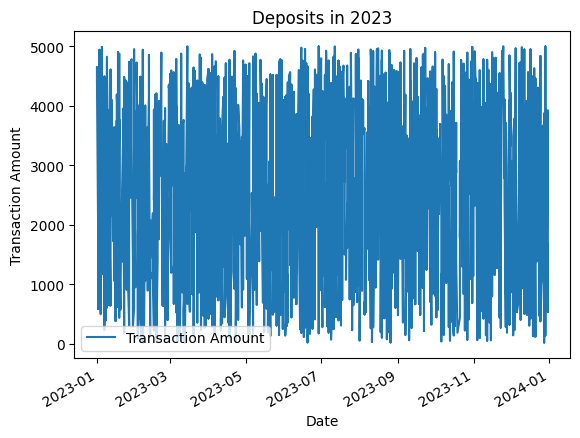

In [56]:
data_2023_deposit.plot(grid = False)
import matplotlib.pyplot as plt
plt.title("Deposits in 2023")
plt.xlabel("Date")
plt.ylabel("Transaction Amount")

Withdrawals in the year 2023

Text(0, 0.5, 'Transaction Amount')

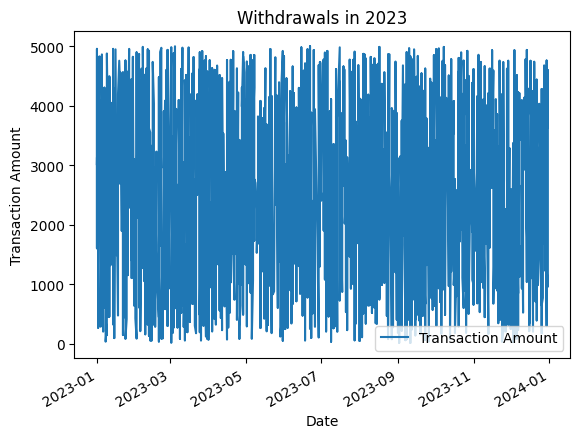

In [57]:
data_2023_withdraw.plot(grid = False)
import matplotlib.pyplot as plt
plt.title("Withdrawals in 2023")
plt.xlabel("Date")
plt.ylabel("Transaction Amount")

Text(0.5, 0, 'Date')

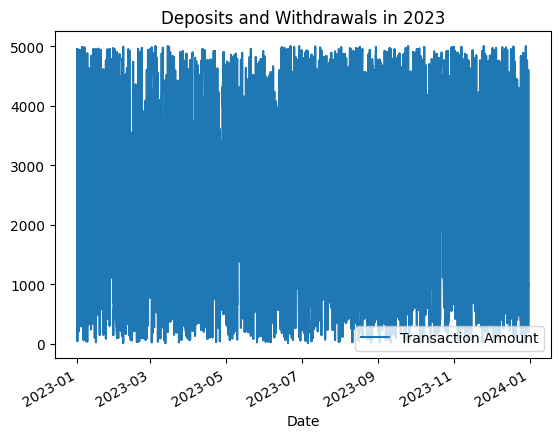

In [58]:
data_2023[['Transaction Amount','Transaction Type']].plot(grid = False,subplots=True)
import matplotlib.pyplot as plt
plt.title("Deposits and Withdrawals in 2023")
plt.xlabel("Date")

# Checking seasonality for the Deposits

In [59]:
monthly_deposits = data_2023_deposit['Transaction Amount'].resample('M').sum()

/tmp/ipython-input-2029601838.py:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



In [60]:
monthly_deposits.head()

,Transaction Amount
Transaction Date,
2023-01-31,357020.03
2023-02-28,278959.94
2023-03-31,379013.46
2023-04-30,315988.07
2023-05-31,387611.52


In [66]:
monthly_deposits.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 12 entries, 2023-01-31 to 2023-12-31
Freq: ME
Data columns (total 1 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction Amount  12 non-null     float64
dtypes: float64(1)
memory usage: 192.0 bytes


In [65]:
monthly_deposits = pd.DataFrame(monthly_deposits)

<Axes: xlabel='y(t)', ylabel='y(t + 1)'>

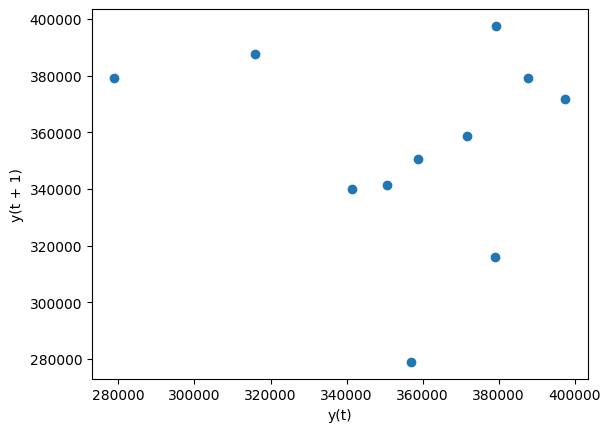

In [67]:
pd.plotting.lag_plot(monthly_deposits['Transaction Amount'],lag = 1)

At lag 3

<Axes: xlabel='y(t)', ylabel='y(t + 3)'>

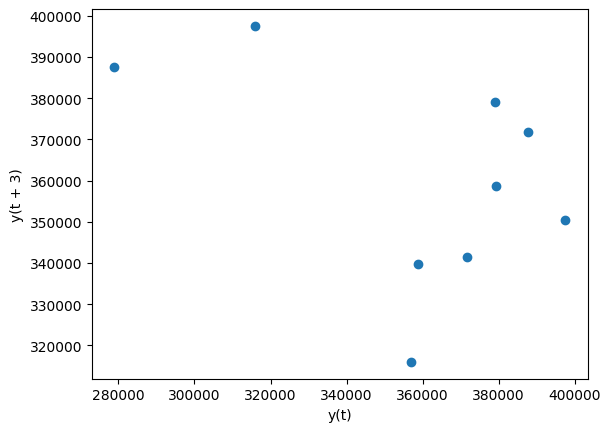

In [68]:
pd.plotting.lag_plot(monthly_deposits['Transaction Amount'],lag = 3)

The purpose of the lag plot is to check whether there is any relationship between the different time frames.

# Autocorrelation

<Axes: xlabel='Lag', ylabel='Autocorrelation'>

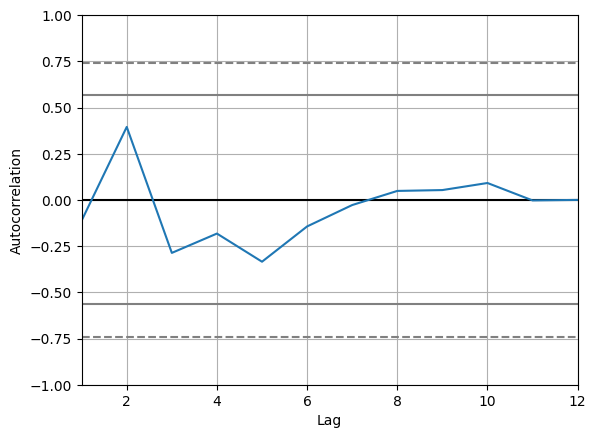

In [69]:
pd.plotting.autocorrelation_plot(monthly_deposits['Transaction Amount'])

In [70]:
# what about yearly
data_new_deposits = data_new[data_new['Transaction Type'] == 'Deposit']
data_new_deposits = data_new_deposits.sort_index()
data_new_deposits.set_index('Transaction Date',inplace=True)
data_new_deposits.index = pd.to_datetime(data_new_deposits.index)

In [71]:
data_new_deposits.head()

,Customer ID,First Name,Last Name,Age,Gender,Address,City,Contact Number,Email,Account Type,...,Minimum Payment Due,Payment Due Date,Last Credit Card Payment Date,Rewards Points,Feedback ID,Feedback Date,Feedback Type,Resolution Status,Resolution Date,Anomaly
Transaction Date,,,,,,,,,,,,,,,,,,,,,
2023-04-27,2,Mark,Taylor,47,Female,Address_2,Louisville,19458794855,mark.taylor@kag.com,Current,...,42.84,11/05/2023,6/16/2023,4306,2,04/07/2023,Complaint,Resolved,8/27/2023,1
2023-04-05,3,Joseph,Flores,25,Female,Address_3,Philadelphia,19458794856,joseph.flores@kag.com,Current,...,162.12,01/08/2023,3/20/2023,4842,3,09/07/2023,Praise,Pending,05/11/2023,1
2023-11-22,7,Joshua,Garcia,43,Male,Address_7,Dallas,19458794860,joshua.garcia@kag.com,Current,...,72.08,3/16/2023,10/09/2023,5745,7,8/20/2023,Complaint,Pending,7/31/2023,1
2023-08-10,8,Christopher,Baker,47,Male,Address_8,Memphis,19458794861,christopher.baker@kag.com,Savings,...,172.51,7/23/2023,7/18/2023,5559,8,8/30/2023,Complaint,Pending,12/19/2023,1
2023-12-29,10,William,Robinson,55,Other,Address_10,Washington,19458794863,william.robinson@kag.com,Current,...,138.27,11/15/2023,01/07/2023,8226,10,10/20/2023,Complaint,Resolved,4/30/2023,1


/tmp/ipython-input-3978178160.py:2: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



Text(0.5, 1.0, 'Yearly Autocorrelation for Deposits')

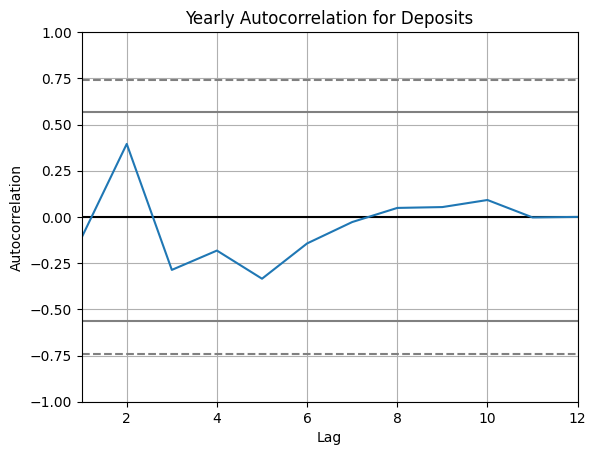

In [73]:
# now we can plot our autocorrelation plot
pd.plotting.autocorrelation_plot(data_new_deposits['Transaction Amount'].resample('M').sum())
plt.title("Yearly Autocorrelation for Deposits")

No strong seasonality detected in deposits.Deposits show some short-term dependencies (mild positive at lag 1, negative around lags 3–5), but none are significant.

Overall : The deposit series appears to be weakly autocorrelated, mostly random noise without a stable seasonal cycle.

# let's do a Time Series Decomposition also to capture if there is any trend

In [74]:
monthly_deposits_1 = data_new_deposits['Transaction Amount'].resample('M').sum()

/tmp/ipython-input-812917063.py:1: FutureWarning:

'M' is deprecated and will be removed in a future version, please use 'ME' instead.



# Running Seasonal Decomposition

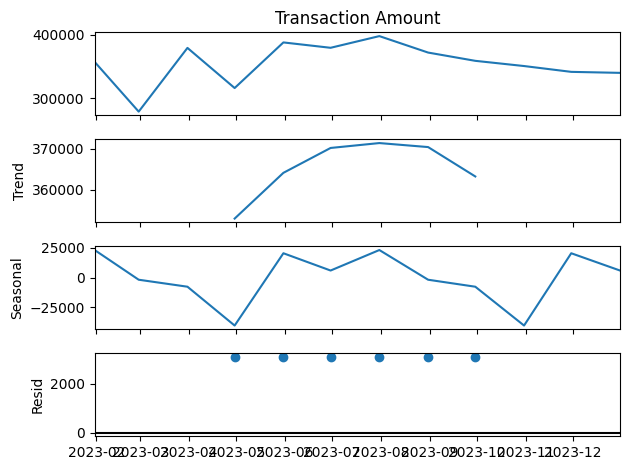

In [78]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition = seasonal_decompose(monthly_deposits_1, model='additive',period = 6)
decomposition.plot()
plt.show()

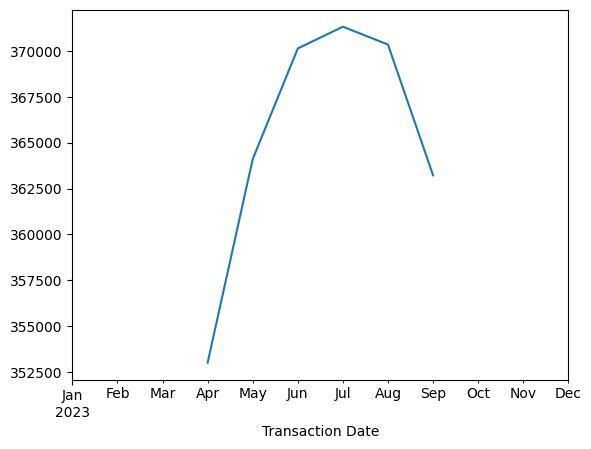

In [79]:
decomposition.trend.plot()
plt.show()

There has been an upward trend in deposits from April to July which is the peak then a negative trend from July to September.